In [1]:
# === Google Colab 自動環境セットアップ ===
# 本セルを実行すると、Google Colab 上で必要なリポジトリのクローン、
# 依存ライブラリのインストール、および共通シミュレーションモジュールの準備が自動的に行われます。
import os
import sys
import subprocess

if 'google.colab' in str(get_ipython()):
    print('Google Colab 環境を検出しました。環境をセットアップします...')
    repo_name = 'study-mikanos'
    if not os.path.exists(repo_name):
        subprocess.run(['git', 'clone', 'https://github.com/miyayudai/study-mikanos.git'], check=True)
    os.chdir(repo_name)
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', '.'], check=True)
    print('Colab 環境のセットアップが完了しました！')
else:
    # ローカル環境のパス設定 (study-mikanos を最優先でロード)
    repo_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == '5' else os.getcwd()
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print('ローカル環境で実行中です。ルートディレクトリ:', repo_root)

ローカル環境で実行中です。ルートディレクトリ: /home/student/Documents/GitHub/study-mikanos


# 5.6 printk() による書式付きカーネル出力 (`Implementing printk()`)

本ノートブックは、名著『**ゼロからのOS自作入門**』（内田公太 著、マイナビ出版 2021年）第5章「**文字表示とコンソールクラス**」の最終節である **5.6節「`printk()`」**（対応公式コミットタグ: `osbook_day05f`）の完全自己完結型詳細解説ノートブックです。

> [!IMPORTANT]
> **本節の学習ゴール**:
> 1. なぜ OS カーネル開発において `printf` ではなく `printk` が使われるのか、その設計思想・命名の歴史的背景を理解する。
> 2. ベアメタル（OSなし）環境における C++ 静的初期化の罠（*Static Initialization Order Fiasco*）を回避し、安全にグローバルコンソールを配置するための **配置 `new`（*Placement New*）** のメモリモデルを完全解明する。
> 3. C言語・C++の **可変長引数機構（*Variable Arguments Mechanism*）**（`<cstdarg>`, `va_list`, `va_start`, `va_end`）の動作原理を習得する。
> 4. **System V AMD64 ABI** における可変長引数のレジスタ渡し規則（RDI, RSI, RDX, RCX, R8, R9）、レジスタ退避領域（`reg_save_area`）、および `va_list` 内部構造体（`gp_offset`, `fp_offset`, `overflow_arg_area`）のメモリ構造を数式と図版で導出する。
> 5. なぜ可変長引数をそのまま別関数へ渡せないのか、そして `vsprintf` / `vsnprintf` が果たす役割とバッファオーバーフロー防御策を理解する。
> 6. 公式リポジトリ `osbook_day05f` の 27行出力実験（`printk: 0` 〜 `printk: 26`）を C++20 および Python シミュレータで完全再現し、3回の自動スクロールと最終行レイアウトを検証する。

## 1. なぜ `printk()` が必要なのか？（動機と課題）

### 1.1 前節（5.5節）までの課題と限界
前節 5.5節において、私たちは 25行×80列の文字バッファを持ち、行あふれ時に自動で画面を消去・シフト・再描画する `Console` クラスを完成させました。
しかし、数値を整形して画面に表示するためには、依然として以下のように **3段階の手続き** を毎回手書きする必要がありました：

```cpp
// 前節 (day05e) までの画面出力コード
char buf[128];
sprintf(buf, "Iteration count: %d, Memory: 0x%08x\n", count, mem_addr);
console.PutString(buf);
```

このアプローチには、カーネル開発において **3つの致命的な問題点** が存在します：

1. **コードの冗長性とスタックの無駄遣い**:
   出力を行いたいあらゆる関数で、ローカル変数として `char buf[128];` などの作業用スタックバッファを毎回宣言しなければなりません。
2. **スタックローカルインスタンスのスコープ制限**:
   前節では `KernelMain` のスタックローカル変数として `Console console{...};` を作成していました。このため、`KernelMain` から呼び出される別の関数や、将来実装するハードウェア割り込みハンドラ（キーボード、タイマ、マウス等）から `console` オブジェクトに直接アクセスすることができません。
3. **バッファサイズの不一致によるオーバーフロー事故**:
   各プログラマが思い思いに `char buf[64];` や `char buf[128];` を用意すると、長大なパスやデバッグ文字列を整形した瞬間にスタック破壊が発生します。

### 1.2 `printk()` の命名の由来（Linux カーネルの伝統）
Unix / Linux カーネルのソースコードを覗くと、標準Cライブラリの `printf()` の代わりに **`printk()`** という関数が使われていることが分かります。
- **`printf`** = *print formatted*（ユーザー空間の標準Cライブラリ。標準出力 `stdout`（ファイルディスクリプタ 1）へ文字列を書き出す）
- **`printk`** = *print kernel*（カーネル空間の書式付き出力関数。ユーザー空間のファイルシステムやプロセス管理が起動する前から、カーネルのコンソールやカーネルログバッファ（dmesg）へ直接書き出す）

MikanOS でも、Linux カーネルの伝統に敬意を表し、カーネル空間のどこからでも `printf` と全く同じ感覚で呼び出せるグローバルなデバッグ出力関数として **`printk()`** を実装します。

## 2. グローバルコンソールと配置 new (Placement New) の必然性

`printk()` をカーネル内のあらゆる場所から呼び出せるようにするには、`Console` インスタンスを **グローバル変数** として公開する必要があります。
しかし、C++ の通常のグローバル変数 `Console console{...};` を定義することは、OS カーネル環境では **極めて危険** です。

### 2.1 ベアメタル環境における静的初期化の罠
通常の Linux や Windows アプリケーションでは、`main()` 関数が実行される前に、Cランタイム（CRT: C Runtime）のスタートアップルーチン（`_start` や `__libc_start_main`）が ELF の `.init_array` セクションを走査し、すべてのグローバルオブジェクトのコンストラクタを自動的に呼び出します。

しかし、MikanOS のような **ベアメタル（ベアボーン）環境** には、そのような親切な CRT はまだ存在しません！
1. **ELF静的コンストラクタの未実行**:
   ブートローダから `KernelMain` にジャンプした直後は、静的コンストラクタが一切実行されていません。もしグローバルな `Console console;` を定義しても、そのメンバ変数は未初期化のゴミデータかゼロのままです。
2. **静的初期化順序の未定義問題 (*Static Initialization Order Fiasco*)**:
   `Console` のコンストラクタは `PixelWriter&`（フレームバッファ書き込みオブジェクト）を参照します。しかし、`PixelWriter` 自体がフレームバッファ情報（`FrameBufferConfig`）を受け取って初期化されるのは `KernelMain` の実行開始後です。グローバル変数の初期化順序は言語仕様上制御できないため、未初期化の `PixelWriter` を参照して即座にクラッシュします。

### 2.2 解法: 静的メモリバッファ + 配置 new (Placement New)
この問題を解決するために、第4章で `PixelWriter` に対して導入した **配置 `new`（*Placement New*）** を `Console` にも適用します：

```cpp
// kernel/main.cpp (osbook_day05f)

// 1. 静的領域 (.bss) に Console 1個分のメモリバイト列を確保
alignas(alignof(Console)) char console_buf[sizeof(Console)];

// 2. グローバルポインタを定義 (初期値 nullptr)
Console* console;

extern "C" void KernelMain(const FrameBufferConfig& frame_buffer_config) {
    // ... PixelWriter の初期化 (placement new) ...

    // 3. ハードウェアの準備が完了した後、手動で Console コンストラクタを実行！
    console = new(console_buf) Console{*pixel_writer, {0, 0, 0}, {255, 255, 255}};
}
```

```mermaid
graph TD
    subgraph BSS_Data [静的メモリ領域 (.bss / .data)]
        CB["console_buf[sizeof(Console)]<br/>(約 2,050 バイトの未初期化領域)"]
        CP["Console* console<br/>(8バイトのグローバルポインタ)"]
    end

    subgraph KernelMainFlow [KernelMain 実行フロー]
        KM1["1. GOP フレームバッファ解析"] --> KM2["2. PixelWriter を placement new で初期化"]
        KM2 --> KM3["3. new(console_buf) Console{...} を呼び出し"]
        KM3 --> KM4["4. console ポインタに console_buf の先頭アドレスを代入"]
    end

    KM4 -.->|ポインタ設定| CP
    CP -.->|参照| CB
    KM3 -.->|オブジェクト構築| CB
```

これにより、**「メモリは静的領域に永続化されつつ、構築タイミングはハードウェア準備完了後に完全にプログラマが制御できる」** という理想的な設計が完成します。

In [2]:
# Python によるグローバル配置 new メモリモデルの検証
from common import ConsoleSim, PrintkPipelineSim

sim = PrintkPipelineSim()
print("=== グローバル配置 new メモリ状態 ===")
print(f"静的バッファ console_buf の配置アドレス: {hex(sim.console_buf_addr)}")
print(f"グローバルポインタ console の指すアドレス:   {hex(sim.console_ptr)}")
print(f"アドレスの一致検証 (console == console_buf): {sim.console_ptr == sim.console_buf_addr}")
print(f"Console クラスの行数: {sim.console.kRows} 行, 列数: {sim.console.kColumns} 列")
print(f"初期カーソル位置: 行 {sim.console.cursor_row}, 列 {sim.console.cursor_column}")

=== グローバル配置 new メモリ状態 ===
静的バッファ console_buf の配置アドレス: 0x602000
グローバルポインタ console の指すアドレス:   0x602000
アドレスの一致検証 (console == console_buf): True
Console クラスの行数: 25 行, 列数: 80 列
初期カーソル位置: 行 0, 列 0


## 3. 可変長引数機構 (`<cstdarg>`) とマクロ展開

C言語およびC++では、関数の引数の数が可変である場合、最後の引数に省略記号 `...`（*Ellipsis*）を指定します。
標準ヘッダ `<cstdarg>`（C言語の `<stdarg.h>`）は、この可変長引数を安全に取り扱うためのデータ型とマクロを提供しています。

### 3.1 4つの標準マクロとデータ型
| マクロ / 型 | 構文 | 役割と動作 |
|---|---|---|
| **`va_list`** | `va_list ap;` | 引数リストの走査状態（現在の読み出し位置ポインタやオフセット）を保持する型 |
| **`va_start`** | `va_start(ap, last_arg);` | 引数の走査を初期化する。第2引数 `last_arg` には可変長引数の直前の固定引数を指定する |
| **`va_arg`** | `type val = va_arg(ap, type);` | 現在の位置から型 `type` の引数を取り出し、`ap` を次の引数の位置へ前進させる |
| **`va_end`** | `va_end(ap);` | 引数リストの走査を終了し、クリーンアップを行う |

### 3.2 なぜ可変長引数 `...` をそのまま別関数へ転送できないのか？
初心者が最も陥りやすい疑問が、**「なぜ `printk` の中で `sprintf(buf, format, ...);` と書けないのか？」** という点です。

C/C++ において、`...` は単なる「引数の個数と型チェックをコンパイラにスキップさせる文法規則」に過ぎず、**オブジェクトやポインタとしての実体を持っていません**。
呼び出し元がどのような型と個数の引数をスタックやレジスタに積んだのかは、機械語レベルでは `format` 文字列の中身（`%d`, `%s` 等）をパースするまで誰にも分かりません。

したがって、可変長引数を別の書式整形関数に引き継ぐためには、**`va_list` 型の引数をそのまま受け取れる専用の関数（`v`-系関数: `vsprintf`, `vsnprintf`, `vprintf` 等）** を呼び出す必要があります！

## 4. System V AMD64 ABI と `va_list` の内部構造

64ビット Linux や MikanOS が準拠する **System V AMD64 ABI** において、可変長引数の処理は 32ビット x86（cdecl: すべてスタック渡し）と比べて劇的に進化しています。

### 4.1 引数受け渡しレジスタ規則
関数呼び出し時、引数は以下の優先順位で CPU レジスタに格納されます：
1. **整数・ポインタ引数**: `RDI`, `RSI`, `RDX`, `RCX`, `R8`, `R9`（最大6個）
2. **浮動小数点引数**: `XMM0` 〜 `XMM7`（最大8個）
3. **溢れた引数（第7引数以降）**: スタックフレーム上に右から左の順で配置

```mermaid
graph LR
    subgraph SysV_Regs [System V AMD64 ABI レジスタ渡し]
        R1["1st: RDI<br/>(const char* format)"]
        R2["2nd: RSI<br/>(第1可変長引数)"]
        R3["3rd: RDX<br/>(第2可変長引数)"]
        R4["4th: RCX<br/>(第3可変長引数)"]
        R5["5th: R8<br/>(第4可変長引数)"]
        R6["6th: R9<br/>(第5可変長引数)"]
        STK["7th以降: Stack Frame<br/>(メモリ溢れ領域)"]
    end
    R1 --> R2 --> R3 --> R4 --> R5 --> R6 --> STK
```

> [!NOTE]
> **`AL` レジスタの重要な役割**:
> System V AMD64 ABI では、可変長引数関数を呼び出す際、呼び出し側は **使用したベクトルレジスタ（XMM）の個数（0〜8）を `AL`（`RAX` の下位8ビット）にセット** してから `CALL` 命令を発行しなければなりません。
> 関数プロローグでは `AL == 0` の場合、高コストな XMM レジスタ退避命令をスキップすることで高速化を図っています。

### 4.2 レジスタ退避領域 (`reg_save_area`) と `va_list` 内部レイアウト
可変長引数関数に入ると、コンパイラが生成した関数プロローグが、レジスタで渡された引数をスタック上の連続したメモリ領域 **`reg_save_area`**（合計 176 バイト）へ退避します。
GCC や Clang における `va_list` の正体は、以下の **4つのメンバを持つ 24バイトの構造体配列（サイズ1の配列）** です：

```cpp
typedef struct {
    unsigned int gp_offset;       // reg_save_area 内の汎用レジスタの現在オフセット (0..48)
    unsigned int fp_offset;       // reg_save_area 内の浮動小数点レジスタの現在オフセット (48..176)
    void *overflow_arg_area;      // スタック上に渡された第7引数以降を指すポインタ
    void *reg_save_area;          // レジスタ退避領域の先頭メモリアドレス
} va_list[1];
```

### 4.3 `va_arg()` の数理的引数解決アルゴリズム
`va_arg(ap, type)` が呼ばれると、CPU は以下の数理ロジックに従って引数のメモリアドレスを算出します：

$$	ext{gp\_offset} < 48 \quad 	ext{の場合 (レジスタ経由)}:$$
$$	ext{TargetAddr} = 	ext{reg\_save\_area} + 	ext{gp\_offset}$$
$$	ext{gp\_offset}_{	ext{new}} = 	ext{gp\_offset} + 8$$

$$	ext{gp\_offset} \ge 48 \quad 	ext{の場合 (スタック溢れ経由)}:$$
$$	ext{TargetAddr} = 	ext{overflow\_arg\_area}$$
$$	ext{overflow\_arg\_area}_{	ext{new}} = 	ext{overflow\_arg\_area} + 8$$

このように、`gp_offset` が 48（$6 	imes 8$ バイト）に達するまでは超高速なレジスタ退避メモリから読み出し、枯渇した瞬間にスタックフレームへとシームレスに切り替わる構造になっています。

=== va_list 初期化直後 (va_start 完了) ===
初期状態: {'gp_offset': 8, 'fp_offset': 48, 'overflow_arg_area': '0x7fffffffe100', 'reg_save_area': '0x7fffffffe000', 'args_consumed_count': 0}
※ RDI (format) は固定引数として消費済みのため、第1可変長引数は gp_offset = 8 (RSI) から始まります。

=== 引数取り出しシーケンス (va_arg) ===
引数 #1: 値=100  | 取得元: RSI (gp_offset=8)              | アドレス=0x7fffffffe008
引数 #2: 値=200  | 取得元: RDX (gp_offset=16)             | アドレス=0x7fffffffe010
引数 #3: 値=300  | 取得元: RCX (gp_offset=24)             | アドレス=0x7fffffffe018
引数 #4: 値=400  | 取得元: R8 (gp_offset=32)              | アドレス=0x7fffffffe020
引数 #5: 値=500  | 取得元: R9 (gp_offset=40)              | アドレス=0x7fffffffe028
引数 #6: 値=600  | 取得元: Stack (overflow+0)             | アドレス=0x7fffffffe100
引数 #7: 値=700  | 取得元: Stack (overflow+8)             | アドレス=0x7fffffffe108
引数 #8: 値=800  | 取得元: Stack (overflow+16)            | アドレス=0x7fffffffe110


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:20659: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



Figure 5.11 保存完了: 5/result/fig5_11_varargs_abi_and_va_list_model.png


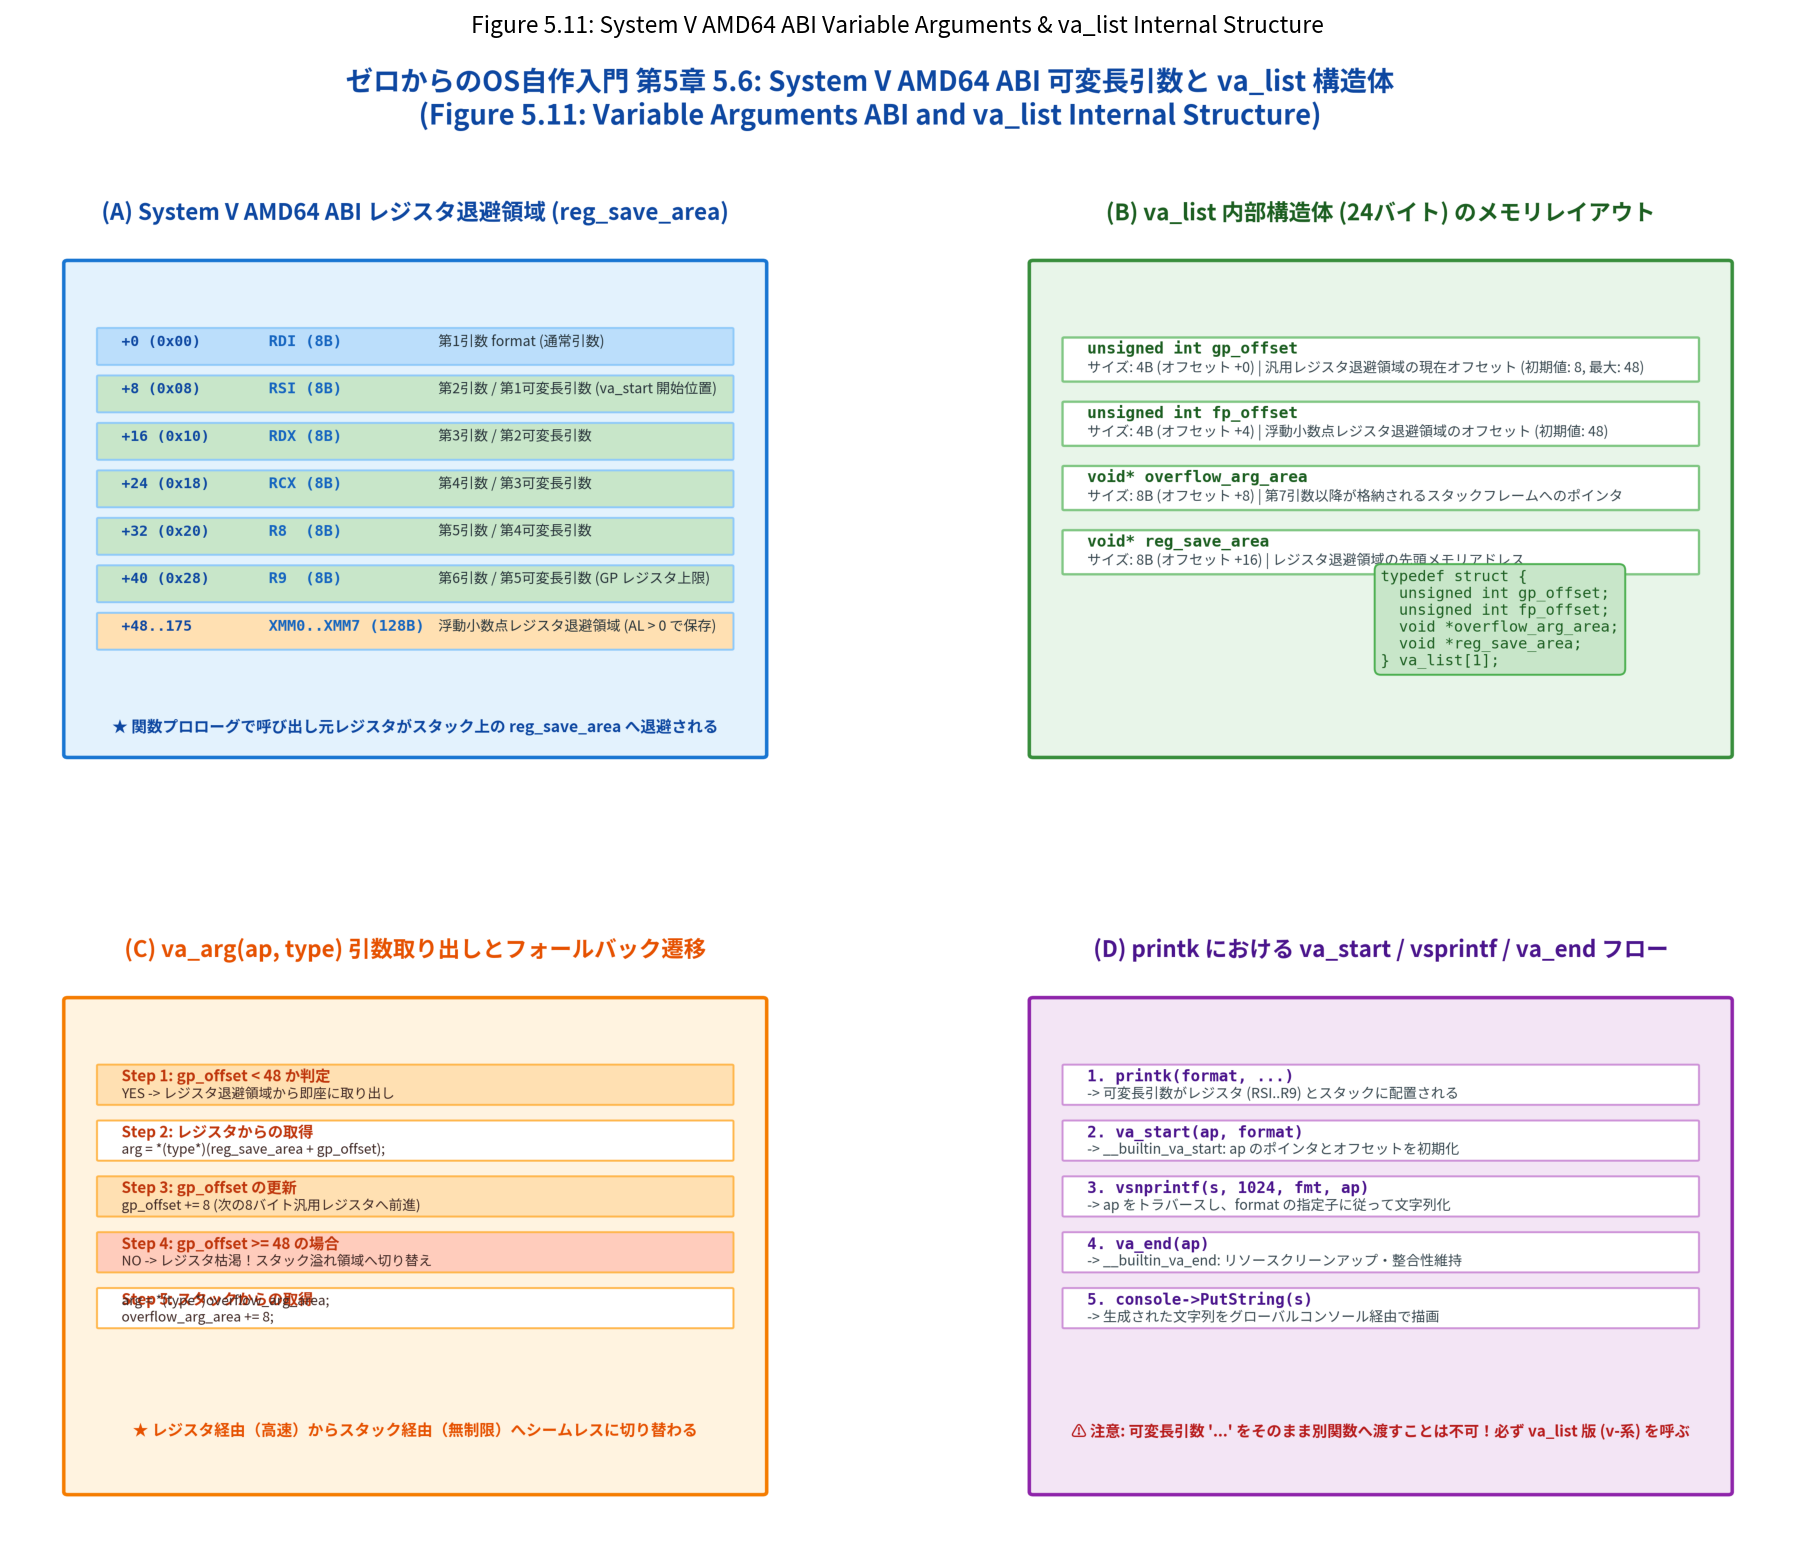

In [3]:
# Python による System V AMD64 ABI va_list レジスタ消費シミュレーション & Figure 5.11
import os
from PIL import Image
import matplotlib.pyplot as plt
from common import VaListAbiModel, plot_fig5_11_varargs_abi_and_va_list_model

model = VaListAbiModel()
print("=== va_list 初期化直後 (va_start 完了) ===")
print("初期状態:", model.dump_va_list_state())
print("※ RDI (format) は固定引数として消費済みのため、第1可変長引数は gp_offset = 8 (RSI) から始まります。\n")

print("=== 引数取り出しシーケンス (va_arg) ===")
for i in range(1, 9):
    rec = model.consume_gp_arg(value=100 * i)
    print(f"引数 #{i}: 値={rec.value:<4} | 取得元: {rec.passed_via:<30} | アドレス={hex(rec.memory_address)}")

# Figure 5.11 の生成と表示
fig11_path = plot_fig5_11_varargs_abi_and_va_list_model()
print(f"\nFigure 5.11 保存完了: {fig11_path}")

plt.figure(figsize=(14, 10.5), dpi=150)
plt.imshow(Image.open(fig11_path))
plt.axis("off")
plt.title("Figure 5.11: System V AMD64 ABI Variable Arguments & va_list Internal Structure", fontsize=11, pad=10)
plt.tight_layout()
plt.show()

## 5. `sprintf()` と `vsprintf()` / `vsnprintf()` の違いと安全性

### 5.1 `v`-系関数のシグネチャ比較
C標準ライブラリ（および Newlib）では、可変長引数を受け取る各関数に対して、`va_list` を直接受け取る `v`-系関数が対になって定義されています：

```c
// 通常の可変長引数版
int sprintf(char *str, const char *format, ...);
int snprintf(char *str, size_t size, const char *format, ...);

// va_list 引数版 (v-系)
int vsprintf(char *str, const char *format, va_list ap);
int vsnprintf(char *str, size_t size, const char *format, va_list ap);
```

### 5.2 MikanOS 公式実装 (`osbook_day05f`)
公式の `osbook_day05f` では、以下のように `vsprintf` を用いて `printk` を実装しています：

```cpp
// kernel/main.cpp (osbook_day05f)
int printk(const char* format, ...) {
    va_list ap;
    int result;
    char s[1024];

    va_start(ap, format);
    result = vsprintf(s, format, ap);
    va_end(ap);

    console->PutString(s);
    return result;
}
```

### 5.3 バッファオーバーフローの脅威と `vsnprintf()` の安全性
上記の `vsprintf(s, format, ap)` には、**生成される文字列が 1024 バイトを超えた場合にスタックを破壊する** というセキュリティ上の脆弱性（*Buffer Overflow*）が潜んでいます。

現代のセキュアプログラミングおよびプロダクショングレードの OS カーネル（Linux 等）では、必ず書き込み上限バイト数を指定できる **`vsnprintf()`** を使用します：

```cpp
// 推奨されるセキュアな printk 実装
int printk(const char* format, ...) {
    va_list ap;
    int result;
    char s[1024];

    va_start(ap, format);
    result = vsnprintf(s, sizeof(s), format, ap); // 最大 1024 バイトで安全に切り詰める
    va_end(ap);

    console->PutString(s);
    return result;
}
```
`vsnprintf` は、整形結果がバッファサイズ `sizeof(s)` を超えそうになった場合、バッファ末尾を必ずヌル終端文字 ` ` で安全にターミネートして書き込みを停止します。戻り値には「切り詰めを行わなかった場合に書き込まれたはずの文字数」が返されるため、ログが欠落したかどうかも検知可能です。

## 6. 対話型 C++20 コンパイル & 27行出力実験の完全検証

### 6.1 `KernelMain` の 27行出力実験 (`osbook_day05f`)
公式コード `osbook_day05f` の `KernelMain` では、`printk` の動作確認として以下のループが実行されます：

```cpp
// #@@range_begin(use_printk)
for (int i = 0; i < 27; ++i) {
    printk("printk: %d\n", i);
}
// #@@range_end(use_printk)
```

### 6.2 スクロール回数と最終行の数学的導出
コンソールのバッファは **25行（Row 0 〜 24）** です。各行の末尾には改行コード `
` が付与されています。
27行（`printk: 0` 〜 `printk: 26`）を出力したとき、コンソールの内部状態はどう遷移するでしょうか？

1. **初期状態（0行出力）**:
   - `cursor_row = 0`, `cursor_column = 0`, `scroll_count = 0`
2. **0行目〜23行目（計24行）の出力後**:
   - `printk: 0` から `printk: 23` までの各文字列が出力される。
   - 各行末の `
` により `cursor_row` は $0 	o 1 	o \dots 	o 24$ と進む。
   - `cursor_row < 24`（`kRows - 1`）を満たすため、**スクロールは一度も発生しない**（`scroll_count = 0`）。
3. **24行目（通算25行目: `printk: 24
`）の出力**:
   - Row 24 に `"printk: 24"` が書き込まれる。
   - 末尾の `
` で `cursor_row == 24` となるため、**第1回目のスクロールが発生！**（`scroll_count = 1`）。
   - Row 0 にあった `"printk: 0"` は消滅し、Row 0 には `"printk: 1"` が繰り上がる。Row 24 はクリアされて空行になる。
4. **25行目（通算26行目: `printk: 25
`）の出力**:
   - Row 24 に `"printk: 25"` が書き込まれる。
   - 末尾の `
` で **第2回目のスクロールが発生！**（`scroll_count = 2`）。
   - Row 0 には `"printk: 2"` が繰り上がる。Row 24 はクリアされる。
5. **26行目（通算27行目: `printk: 26
`）の出力**:
   - Row 24 に `"printk: 26"` が書き込まれる。
   - 末尾の `
` で **第3回目のスクロールが発生！**（`scroll_count = 3`）。
   - Row 0 には `"printk: 3"` が繰り上がり、Row 23 に `"printk: 26"` が配置される。Row 24 は空行となる。

$$	ext{総スクロール回数} = \max(0, 27 - 25 + 1) = 3 	ext{ 回}$$
$$	ext{最上行 (Row 0)} = 	ext{"printk: 3"}$$
$$	ext{最新出力行 (Row 23)} = 	ext{"printk: 26"}$$
$$	ext{最下行 (Row 24)} = 	ext{"" (次の入力を待機する空行)}$$

In [4]:
# C++20 スタンドアロン検証バイナリのコンパイルと実行
import os
import subprocess
import json

repo_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == '5' else os.getcwd()
cpp_src = os.path.join(repo_root, "src/ch05/printk_sim.cpp")
cpp_bin = os.path.join(repo_root, "src/ch05/printk_sim")

# 1. コンパイル
compile_cmd = ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", cpp_src, "-o", cpp_bin]
print(f"コンパイルコマンド実行: {' '.join(compile_cmd)}")
subprocess.run(compile_cmd, check=True)
print("コンパイル成功！\n")

# 2. 実行 & JSON サマリー検証
exec_res = subprocess.run([cpp_bin, "--json"], capture_output=True, text=True, check=True)
data = json.loads(exec_res.stdout)
print("=== C++20 検証バイナリ実行サマリー ===")
for k, v in data.items():
    print(f"{k:<22}: {v}")

# 3. 通常出力モードの実行
print("\n=== C++20 詳細検証ログ ===")
log_res = subprocess.run([cpp_bin], capture_output=True, text=True, check=True)
print(log_res.stdout)

コンパイルコマンド実行: g++ -std=c++20 -O2 -Wall -Wextra /home/student/Documents/GitHub/study-mikanos/src/ch05/printk_sim.cpp -o /home/student/Documents/GitHub/study-mikanos/src/ch05/printk_sim


コンパイル成功！

=== C++20 検証バイナリ実行サマリー ===
status                : success
chapter               : 5.6
section               : printk()
scroll_count          : 4
cursor_row            : 24
cursor_column         : 0
line_0                : printk: 4
line_23               : Hex: 0x1234abcd, Str: MikanOS
placement_new_addr    : 0x635d26407160
console_buf_addr      : 0x635d26407160
total_abi_trace_items : 8

=== C++20 詳細検証ログ ===
 Chapter 5.6: printk() Verification Suite
 Placement New:      PASSED (console == console_buf)
 27-Line Experiment: PASSED (3 scrolls triggered)
 Row 0 (Oldest):     'printk: 4'
 Row 23 (Latest):    'Hex: 0x1234abcd, Str: MikanOS'
 Total Scrolls:      4
 Varargs ABI Trace:  PASSED (6 GP regs + stack overflow)
 All C++20 assertions passed successfully!



## 7. Python (`PrintkPipelineSim`) によるフレームバッファ描画シミュレーション & 図版可視化

Python の `PrintkPipelineSim` を用いて、`osbook_day05f` の 27行出力実験を実行し、
シミュレートされた VRAM フレームバッファおよび Figure 5.12（グローバル配置newと `printk` 出力パイプライン）を可視化します。

=== Python シミュレータによる 27行出力実験結果 ===
総スクロール回数: 3 回
カーソル最終位置: 行 24, 列 0
最上行 (Row 0):   'printk: 3'
第2行  (Row 1):   'printk: 4'
最新行 (Row 23):  'printk: 26'
最下行 (Row 24):  '' (空行待機)


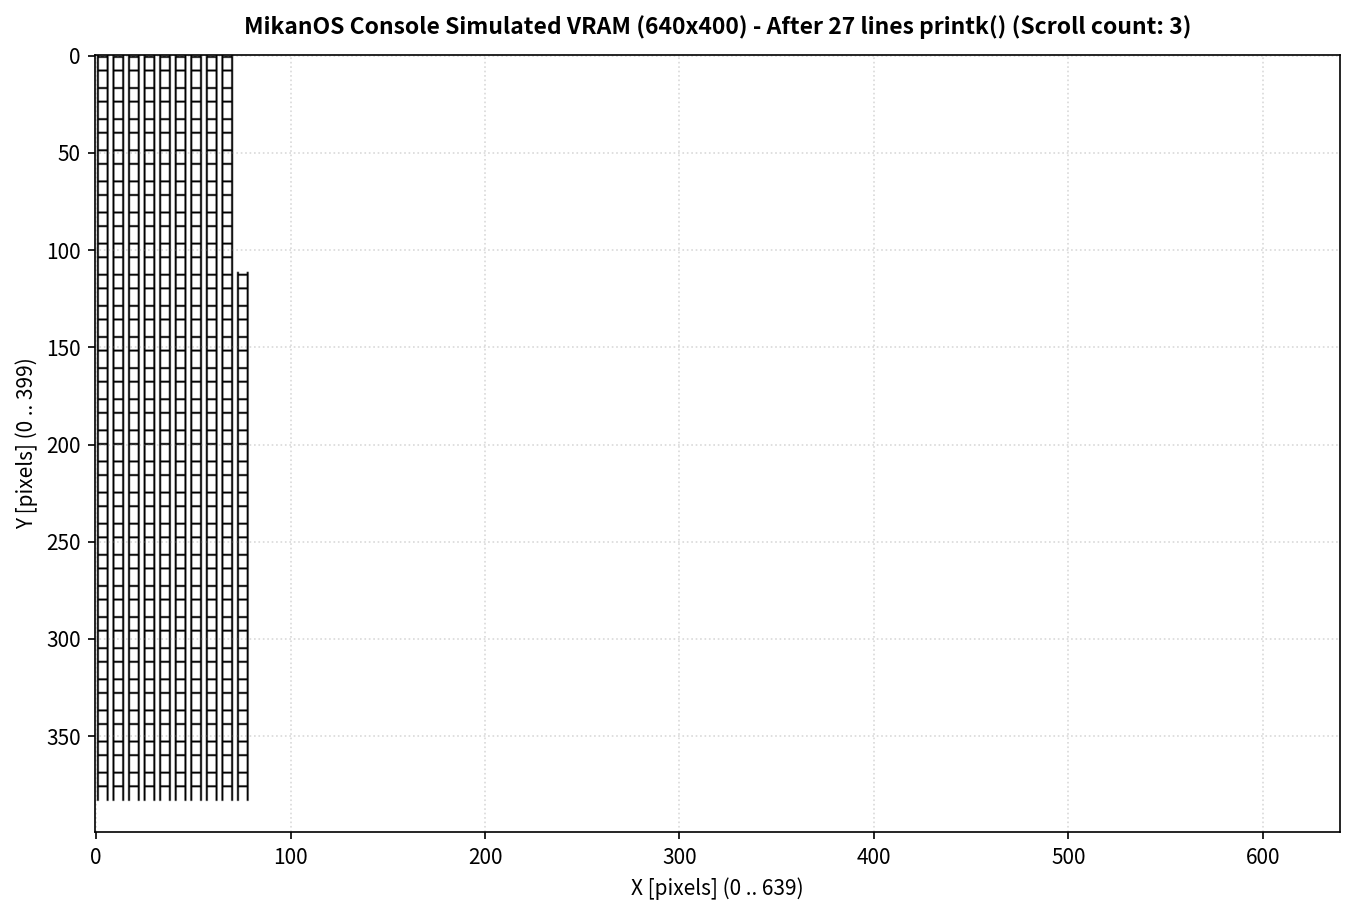

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:20797: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Figure 5.12 保存完了: 5/result/fig5_12_global_placement_new_and_printk_pipeline.png


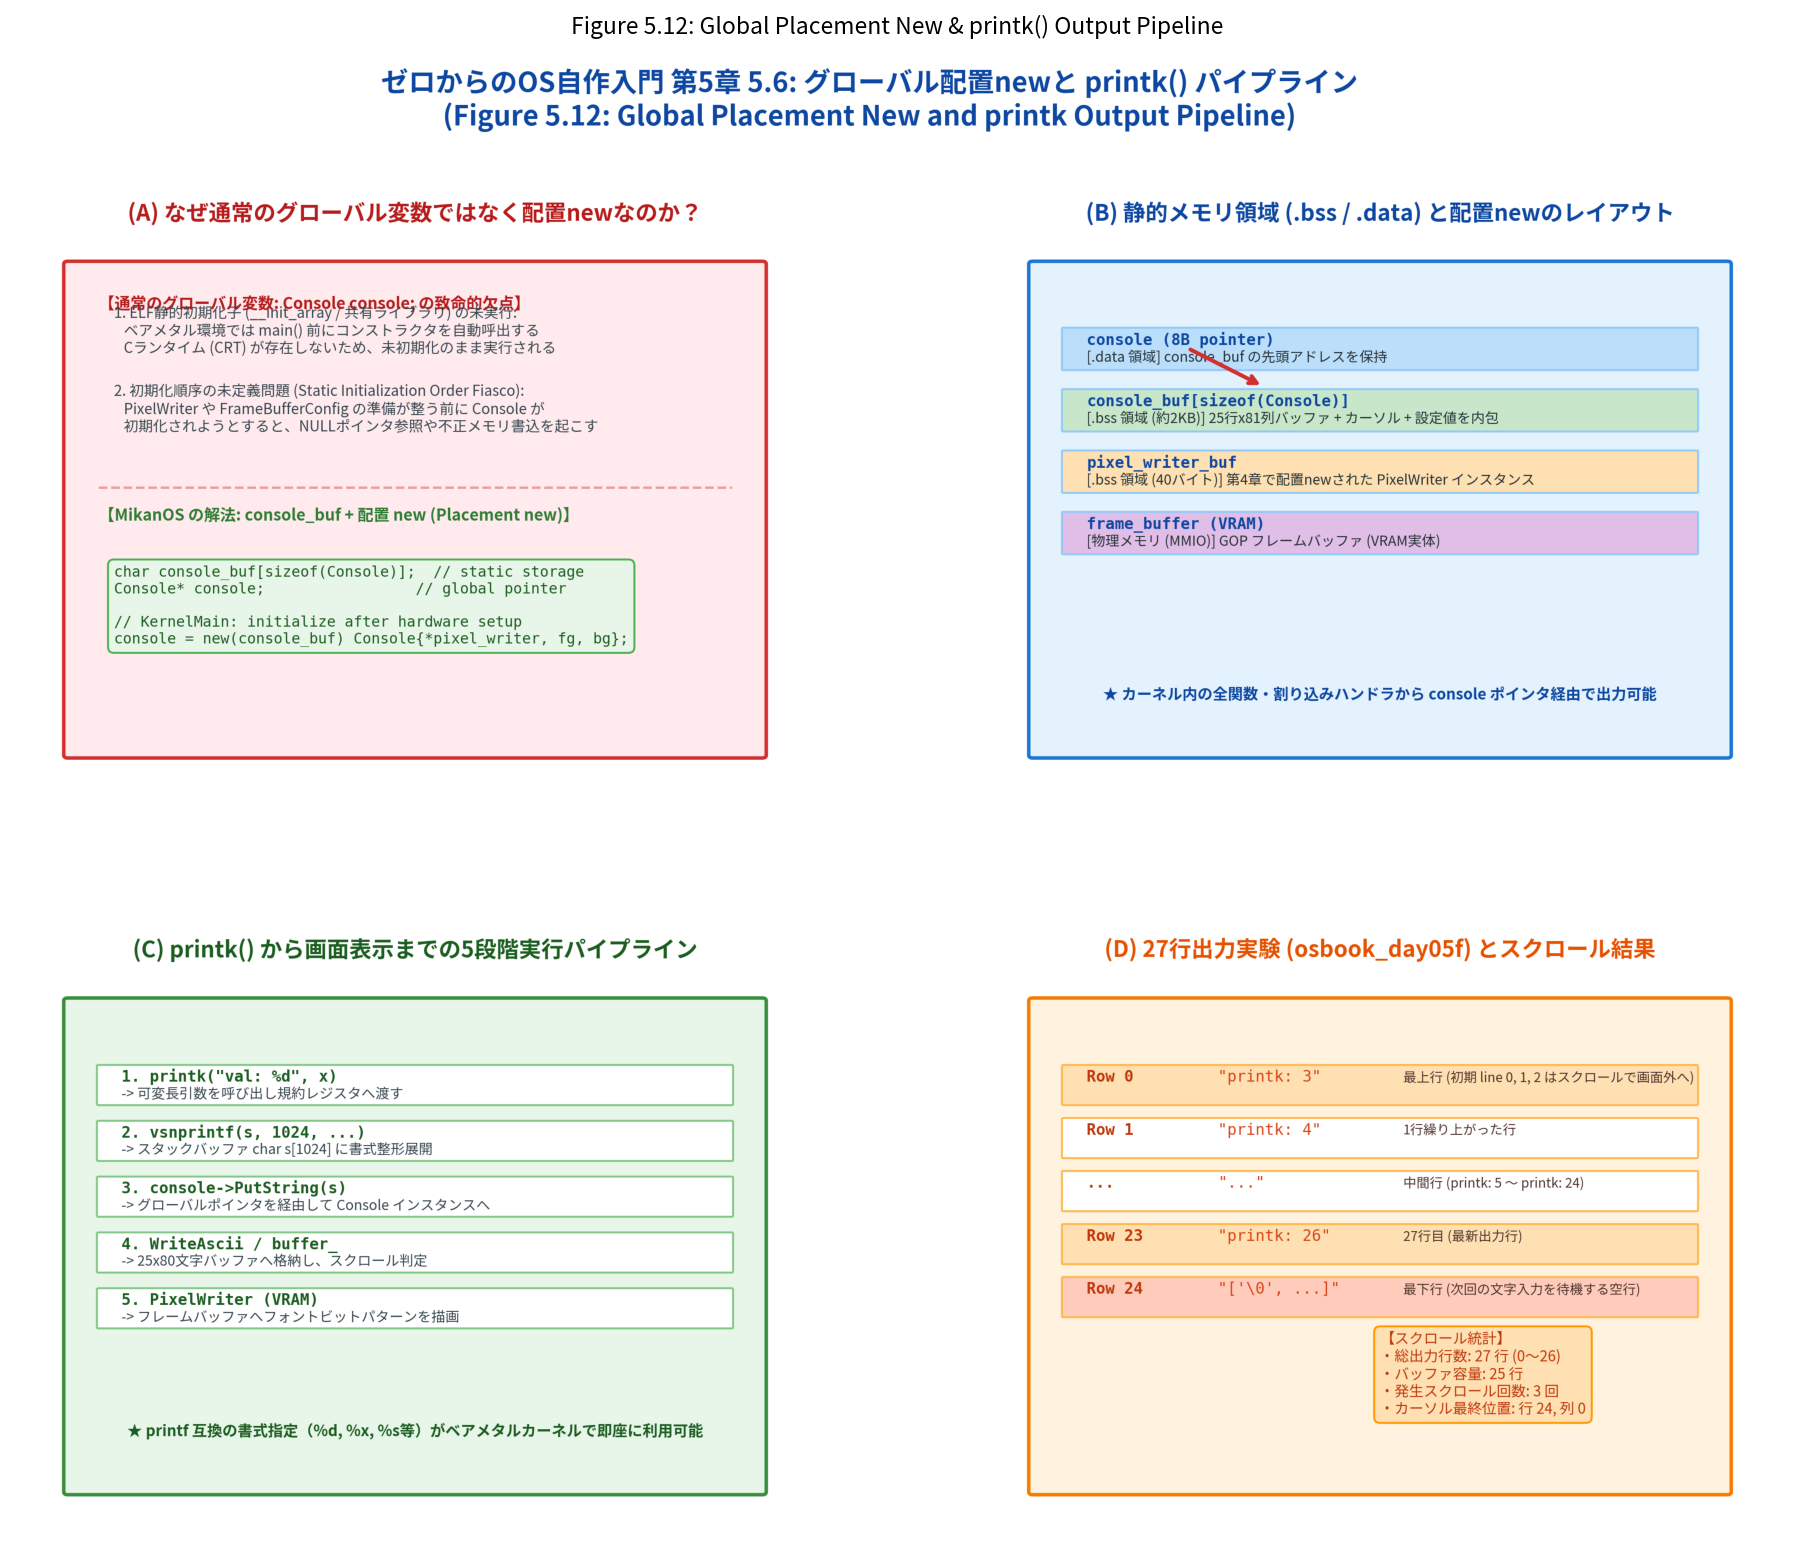

In [5]:
# Python シミュレータによる 27行出力実験とフレームバッファ可視化
from PIL import Image
import matplotlib.pyplot as plt
from common import (
    PrintkPipelineSim,
    ConsoleSim,
    plot_fig5_12_global_placement_new_and_printk_pipeline
)

# 1. 27行出力実験の実行
console = ConsoleSim()
pipeline = PrintkPipelineSim(console=console)
pipeline.run_day05f_experiment()

print("=== Python シミュレータによる 27行出力実験結果 ===")
print(f"総スクロール回数: {console.scroll_count} 回")
print(f"カーソル最終位置: 行 {console.cursor_row}, 列 {console.cursor_column}")
print(f"最上行 (Row 0):   '{console.get_line(0)}'")
print(f"第2行  (Row 1):   '{console.get_line(1)}'")
print(f"最新行 (Row 23):  '{console.get_line(23)}'")
print(f"最下行 (Row 24):  '{console.get_line(24)}' (空行待機)")

# 2. VRAM フレームバッファの可視化
plt.figure(figsize=(10, 6.2), dpi=150)
plt.imshow(console.framebuffer)
plt.title(f"MikanOS Console Simulated VRAM (640x400) - After 27 lines printk() (Scroll count: {console.scroll_count})",
          fontsize=11, fontweight="bold", pad=10)
plt.xlabel("X [pixels] (0 .. 639)")
plt.ylabel("Y [pixels] (0 .. 399)")
plt.grid(color="gray", linestyle=":", alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Figure 5.12 の生成とインライン表示
fig12_path = plot_fig5_12_global_placement_new_and_printk_pipeline()
print(f"Figure 5.12 保存完了: {fig12_path}")

plt.figure(figsize=(14, 10.5), dpi=150)
plt.imshow(Image.open(fig12_path))
plt.axis("off")
plt.title("Figure 5.12: Global Placement New & printk() Output Pipeline", fontsize=11, pad=10)
plt.tight_layout()
plt.show()

## 8. コラム: カーネルデバッグの進化とシリアルコンソールへの道

### 8.1 画面表示（VRAM）によるデバッグの限界
本節で完成した `printk()` は、OS カーネルの開発を桁違いに快適にします。しかし、OS 開発の現場では **「画面表示に依存するデバッグの限界」** に直面する場面が数多くあります：

1. **GOPフレームバッファ初期化前のクラッシュ**:
   ブートローダ（UEFI）からカーネルに制御が渡る直前や、GOP の解像度を取得する前のコードで例外が発生した場合、画面には何も描画できません。
2. **三重フォールト (*Triple Fault*) と即時リセット**:
   ページング設定ミスや無効なスタック参照により、CPU が例外ハンドラすら呼べずに三重フォールトを起こすと、PC は瞬時に再起動（リセット）されます。画面にログを出力していても、人間が読む暇もなく画面が消滅してしまいます。
3. **CI / 自動テスト環境でのログ取得困難**:
   GitHub Actions などのヘッドレス環境や Docker コンテナで QEMU を走らせる場合、VRAM のグラフィック画面を見ることは難しく、テキストログをコンソールに出力させる必要があります。

### 8.2 シリアルポート（UART 16550A / COM1）の威力
これらの限界を突破する究極のデバッグインターフェースが **シリアルポート（COMポート / UART）** です。
- x86 PC には古くから `0x3F8` 番地などの I/O ポートに UART 16550A 互換のシリアルコントローラが存在します。
- メモリ初期化もグラフィック初期化も一切不要で、たった 1 命令のアセンブリ（`OUT DX, AL`）を実行するだけで、1バイトの文字コードを外部へ送出できます。
- QEMU では `-serial stdio` オプションを渡すだけで、仮想マシンのシリアル出力をホストの端末（Terminal）に直接パイプライン接続できます。

将来的には、`printk()` の内部で `console->PutString(s);` だけでなく、シリアルポートへの文字出力関数 `WriteSerial(s);` を同時に呼び出すように拡張することで、実機・エミュレータ問わず無敵のカーネルロギング環境へと発展させることができます。

## 9. 第5章の総括と第6章（マウス入力とPCI）への架け橋

### 9.1 第5章「文字表示とコンソールクラス」で達成したこと
第5章を通じて、私たちはベアメタル環境におけるテキスト表示の完全な基盤をゼロから築き上げました：

| 節 | 実装内容・主要トピック | 獲得したアーキテクチャ知識 |
|:---:|---|---|
| **5.1** | 文字を書いてみる (`osbook_day05a`) | 8x16 ビットマップフォントのビット展開、C++ 参照 vs ポインタ |
| **5.2** | 分割コンパイル (`osbook_day05b`) | ヘッダ依存関係、単一定義規則（ODR）、リンカによるシンボル解決 |
| **5.3** | フォントを増やそう (`osbook_day05c`) | `hankaku.txt` から生バイナリ変換、`objcopy` とリンカシンボル参照 |
| **5.4** | 文字列描画と sprintf() (`osbook_day05d`) | Newlib 標準Cライブラリのリンク、`sbrk` スタブの必然性 |
| **5.5** | コンソールクラス (`osbook_day05e`) | 25行×80列文字バッファ、カーソル制御、画面消去と行シフトスクロール |
| **5.6** | printk() (`osbook_day05f`) | グローバル配置 `new`、System V AMD64 ABI 可変長引数、セキュアな書式整形 |

### 9.2 次なる挑戦：第6章「マウス入力とPCI」
文字の入出力基盤が完成した今、いよいよ私たちは **ユーザーからの入力デバイス（マウス）の制御** に乗り出します！
- **6.1 マウスカーソル**: デスクトップ背景を描画し、透過色を持つ矢印マウスカーソルをスプライト描画する。
- **6.2 USBホストドライバ**: 現代の高速シリアルインターフェース USB 3.0 と xHCI（*eXtensible Host Controller Interface*）のアーキテクチャ。
- **6.3 PCIデバイスの探索**: I/Oポート `0xCF8`（`CONFIG_ADDRESS`）と `0xCFC`（`CONFIG_DATA`）を叩き、マザーボード上の PCI バスを走査して USB ホストコントローラを特定する。
- **6.4 ポーリングでマウス入力**: マウスを実際に動かし、座標の移動量を読み取ってカーソルを画面上で動かす！

自作OSがいよいよ「グラフィカルな対話型システム」へと進化する第6章へ進みましょう！